**Linear LogReg probe PCA on English 5000 data ONLY ON MBERT, new surprise and fear w/o emojis and clean code and BRIGHTER+XED English + German test set + mDeBERTa, with BALANCED calibration AND (printed) PROBE WEIGHTS! ALSO ADDED EVALUATION TO PROJECTION METHODS (+ probe). Additional German calibration and a 6D classifier + probe training on hand labeled data. Estonian is smaller. CORRECT ONE!!**

In [1]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_FILE = "combined_english_cleaned_surprise_and_fear_balanced.csv"
MAX_LENGTH = 128
BATCH_SIZE = 32
RANDOM_STATE = 42

In [3]:
# Pooling

def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

    summed = torch.sum(token_embeddings * input_mask_expanded, dim=1)
    counts = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
    return summed / counts

def cls_pooling(model_output):
    return model_output.last_hidden_state[:, 0, :]

In [4]:
# Encoding
def encode_texts(text_list, tokenizer, model, device, batch_size=32, max_length=128):
    mean_embs = []
    cls_embs = []

    with torch.no_grad():
        for i in tqdm(range(0, len(text_list), batch_size), desc="Encoding"):
            batch_texts = text_list[i:i + batch_size]

            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt"
            )
            encoded = {k: v.to(device) for k, v in encoded.items()}

            outputs = model(**encoded)

            mean_emb = mean_pooling(outputs, encoded["attention_mask"])
            cls_emb = cls_pooling(outputs)

            mean_embs.append(mean_emb.cpu().numpy())
            cls_embs.append(cls_emb.cpu().numpy())

    return np.vstack(mean_embs), np.vstack(cls_embs)

In [5]:
# Centroids

def compute_centroids(embeddings, df, emotion_order):
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(embeddings[mask].mean(axis=0))
    centroids = np.vstack(centroids)
    return normalize(centroids, norm="l2")

In [6]:
# PCA

def plot_centroids_in_full_pca_2d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=160)
        plt.text(
            centroids_2d[i, 0],
            centroids_2d[i, 1],
            emotion,
            fontsize=11,
            ha='center',
            va='center'
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

def plot_centroids_in_full_pca_3d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_3d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(emotion_order):
        ax.scatter(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            s=140
        )
        ax.text(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            emotion,
            fontsize=11
        )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

In [7]:
# Probe training
def train_probe(embeddings, labels, name):
    X_train, X_test, y_train, y_test = train_test_split(
        embeddings,
        labels,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=labels
    )

    clf = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    print(f"\n=== {name} probe ===")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
    print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))
    print(classification_report(y_test, y_pred, digits=3))

    return clf

In [8]:
# Linear probe PCA
def get_probe_space(probe, embeddings, use_probabilities=False):
    if use_probabilities:
        return probe.predict_proba(embeddings)
    else:
        scores = probe.decision_function(embeddings)

        if scores.ndim == 1:
            scores = scores[:, None]

        return scores


def plot_probe_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            label=emotion,
            alpha=0.35,
            s=10
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


def plot_probe_centroids_pca_2d(probe, embeddings, df, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    # centroid in probe space
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(probe_space[mask].mean(axis=0))
    centroids = np.vstack(centroids)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(probe_space)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    dx = (centroids_2d[:, 0].max() - centroids_2d[:, 0].min()) * 0.02
    dy = (centroids_2d[:, 1].max() - centroids_2d[:, 1].min()) * 0.02

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=180)
        plt.text(
            centroids_2d[i, 0] + dx,
            centroids_2d[i, 1] + dy,
            emotion,
            fontsize=11
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()


def plot_probe_kde_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=True):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    # scatter lightly underneath
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            alpha=0.08,
            s=8,
            label=emotion
        )

    # KDE contours if seaborn is available
    try:
        import seaborn as sns

        for emotion in emotion_order:
            mask = (np.array(labels) == emotion)
            sns.kdeplot(
                x=X_2d[mask, 0],
                y=X_2d[mask, 1],
                levels=[0.25, 0.5],
                linewidths=2
            )
    except ImportError:
        print("seaborn not installed, showing scatter only.")

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

In [9]:
# Example prediction
example_texts = [
    "I am so happy and excited about this!",
    "This is disgusting and makes me sick.",
    "I am terrified something bad will happen.",
    "I miss you so much and feel empty.",
    "What a wonderful surprise!",
    "I am furious and cannot stand this anymore."
]

def predict_examples(text_list, tokenizer, model, device, probe, use_mean=True):
    mean_embs, cls_embs = encode_texts(
        text_list, tokenizer, model, device,
        batch_size=8, max_length=MAX_LENGTH
    )

    embs = mean_embs if use_mean else cls_embs
    embs = normalize(embs, norm="l2")

    preds = probe.predict(embs)
    probs = probe.predict_proba(embs)

    for text, pred, prob in zip(text_list, preds, probs):
        top_idx = np.argsort(prob)[::-1][:3]
        top3 = [(probe.classes_[i], round(float(prob[i]), 3)) for i in top_idx]

        print("\nTEXT:", text)
        print("Predicted:", pred)
        print("Top-3:", top3)

In [10]:

# Probe weight analysis

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    if not hasattr(probe, "coef_"):
        raise ValueError("Probe does not expose coef_. This works for LogisticRegression.")
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def plot_probe_weight_cosine_similarity(probe, class_order, title):
    W = get_probe_weight_matrix(probe)
    sim = cosine_similarity(W)
    sim_df = pd.DataFrame(sim, index=class_order, columns=class_order).round(3)

    print(f"\n{title}")
    print(sim_df)

    plt.figure(figsize=(7, 6))
    plt.imshow(sim, interpolation="nearest")
    plt.xticks(range(len(class_order)), class_order, rotation=45, ha="right")
    plt.yticks(range(len(class_order)), class_order)
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return sim_df


def plot_probe_weights_pca_2d(probe, class_order, title):
    """
    PCA on probe weight vectors themselves.
    Each point = one emotion direction.
    """
    W = get_probe_weight_matrix(probe)

    # with few classes, max possible rank is limited
    n_comp = min(2, W.shape[0], W.shape[1])
    pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
    W_2d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(class_order):
        plt.scatter(W_2d[i, 0], W_2d[i, 1], s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], emotion, fontsize=11)

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, pca


def plot_probe_weights_pca_3d(probe, class_order, title):
    W = get_probe_weight_matrix(probe)

    n_comp = min(3, W.shape[0], W.shape[1])
    if n_comp < 3:
        print(f"\n{title}")
        print("Not enough dimensions/classes for 3D PCA.")
        return None, None

    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    W_3d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    # 🔽 ADD THIS BLOCK
    print("\n3D PCA coordinates (per emotion):")
    coords_df = pd.DataFrame(W_3d, columns=["PC1", "PC2", "PC3"])
    coords_df["emotion"] = class_order
    print(coords_df.round(4).to_string(index=False))

    # Also print in Desmos-friendly format
    print("\nDesmos-friendly format:")
    for i, emotion in enumerate(class_order):
        x, y, z = W_3d[i]
        print(f"{emotion}: ({x:.4f}, {y:.4f}, {z:.4f})")

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(class_order):
        ax.scatter(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], s=160)
        ax.text(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], emotion, fontsize=10)

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

    return W_3d, pca


def plot_probe_weights_vs_centroids_pca_2d(probe, centroids, class_order, title):
    """
    Compare probe weight vectors and class centroids in the same PCA space.
    PCA is fit on the combined matrix [weights; centroids].
    """
    W = get_probe_weight_matrix(probe)
    C = normalize(centroids.copy(), norm="l2")

    combined = np.vstack([W, C])

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    combined_2d = pca.fit_transform(combined)

    W_2d = combined_2d[:len(class_order)]
    C_2d = combined_2d[len(class_order):]

    print(f"\n{title}")
    print("Combined shape:", combined.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    for i, emotion in enumerate(class_order):
        # weights
        plt.scatter(W_2d[i, 0], W_2d[i, 1], marker="^", s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], f"{emotion}_W", fontsize=10)

        # centroids
        plt.scatter(C_2d[i, 0], C_2d[i, 1], marker="o", s=180)
        plt.text(C_2d[i, 0], C_2d[i, 1], f"{emotion}_C", fontsize=10)

        # line connecting them
        plt.plot(
            [W_2d[i, 0], C_2d[i, 0]],
            [W_2d[i, 1], C_2d[i, 1]],
            linestyle="--",
            alpha=0.5
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, C_2d, pca


def plot_probe_weight_projection_histograms(probe, embeddings, labels, emotion_order, title_prefix):
    """
    For each emotion direction, project all embeddings onto that weight vector.
    This shows whether the corresponding class tends to score higher along its own direction.
    """
    W = get_probe_weight_matrix(probe)
    X = normalize(embeddings.copy(), norm="l2")
    label_array = np.array(labels)

    for i, emotion in enumerate(emotion_order):
        scores = X @ W[i]

        plt.figure(figsize=(8, 5))
        for e in emotion_order:
            mask = label_array == e
            plt.hist(scores[mask], bins=40, alpha=0.35, label=e, density=True)

        plt.title(f"{title_prefix}: projection onto '{emotion}' weight")
        plt.xlabel("Cosine-like projection score")
        plt.ylabel("Density")
        plt.legend()
        plt.grid(alpha=0.2)
        plt.show()

In [11]:

# Projection-based classifiers

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def predict_with_weight_cosine(embeddings, probe, class_order):
    """
    Classify by cosine similarity between embeddings and probe weight vectors.
    """
    X = normalize(embeddings.copy(), norm="l2")
    W = get_probe_weight_matrix(probe)  # already normalized

    scores = X @ W.T   # cosine-like similarity since both normalized
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def predict_with_prototypes(embeddings, centroids, class_order):
    """
    Classify by nearest normalized class centroid (cosine similarity).
    """
    X = normalize(embeddings.copy(), norm="l2")
    C = normalize(centroids.copy(), norm="l2")

    scores = X @ C.T
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def softmax_np(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


def evaluate_simple_classifier(gold_labels, preds, scores, class_order, name="Classifier"):
    """
    Evaluation for cosine / prototype classifiers.
    Uses softmax(scores) as pseudo-probabilities for log loss + confidence stats.
    """
    probs = softmax_np(scores)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "scores": scores,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }
    
def predict_with_linear_scores(embeddings, probe, class_order, normalize_inputs=False):
    """
    Classify using the probe's raw linear scoring function:
        score_c = x · w_c + b_c

    If normalize_inputs=True, embeddings are L2-normalized first.
    This is still interpretable, but closer to the original logistic probe
    than cosine similarity to normalized weights.
    """
    X = embeddings.copy()
    if normalize_inputs:
        X = normalize(X, norm="l2")

    W = probe.coef_          # shape: (n_classes, dim)
    b = probe.intercept_     # shape: (n_classes,)

    scores = X @ W.T + b
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores

In [12]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def fit_bias_only(X_calib, y_calib, probe, class_order, l2=0.01):
    """
    Freeze probe weights W, learn only bias b on calibration data.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}
    y_idx = np.array([label_to_idx[y] for y in y_calib])

    def objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(np.log(probs[np.arange(len(y_idx)), y_idx] + 1e-12))

        # regularize toward original bias, so calibration does not overfit too much
        penalty = l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    result = minimize(
        objective,
        x0=old_b,
        method="BFGS"
    )

    return result.x


def predict_with_fixed_weights_new_bias(X, probe, new_b, class_order):
    W = probe.coef_.copy()
    scores = X @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, probs, scores


def evaluate_bias_calibrated(X_test, y_test, probe, new_b, class_order, name):
    preds, probs, scores = predict_with_fixed_weights_new_bias(
        X_test,
        probe,
        new_b,
        class_order
    )
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "scores": scores,
        "confusion_matrix": cm_df
    }

In [13]:
# mBERT loading

MODEL_NAME = "google-bert/bert-base-multilingual-cased"

df = pd.read_csv(DATA_FILE)
df["text"] = df["text"].astype(str)
df["emotion"] = df["emotion"].astype(str)

texts = df["text"].tolist()
labels = df["emotion"].tolist()
emotion_order = sorted(df["emotion"].unique())

print("Rows:", len(df))
print("Emotions:", emotion_order)

device = torch.device("cuda" if torch.cuda.is_available() else "mps")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

Rows: 30000
Emotions: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(119547, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropo

In [14]:
# mBERT info

# embeddings
mean_embeddings, cls_embeddings = encode_texts(
    texts, tokenizer, model, device,
    batch_size=BATCH_SIZE, max_length=MAX_LENGTH
)

print("Mean embeddings shape:", mean_embeddings.shape)
print("CLS embeddings shape:", cls_embeddings.shape)

# normalization
mean_embeddings_norm = normalize(mean_embeddings, norm="l2")
cls_embeddings_norm = normalize(cls_embeddings, norm="l2")  

# centroids
mean_centroids = compute_centroids(mean_embeddings_norm, df, emotion_order)
cls_centroids = compute_centroids(cls_embeddings_norm, df, emotion_order)

# cos similarity
mean_centroid_cos = cosine_similarity(mean_centroids)
cls_centroid_cos = cosine_similarity(cls_centroids)

print("\nCosine similarity between mean-pooled centroids:")
print(pd.DataFrame(mean_centroid_cos, index=emotion_order, columns=emotion_order).round(3))

print("\nCosine similarity between CLS centroids:")
print(pd.DataFrame(cls_centroid_cos, index=emotion_order, columns=emotion_order).round(3))



Encoding: 100%|██████████| 938/938 [06:24<00:00,  2.44it/s]


Mean embeddings shape: (30000, 768)
CLS embeddings shape: (30000, 768)

Cosine similarity between mean-pooled centroids:
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.993  0.994  0.984    0.983     0.995
disgust   0.993    1.000  0.993  0.980    0.985     0.991
fear      0.994    0.993  1.000  0.991    0.995     0.996
joy       0.984    0.980  0.991  1.000    0.992     0.991
sadness   0.983    0.985  0.995  0.992    1.000     0.988
surprise  0.995    0.991  0.996  0.991    0.988     1.000

Cosine similarity between CLS centroids:
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.997  0.997  0.990    0.991     0.996
disgust   0.997    1.000  0.997  0.987    0.993     0.994
fear      0.997    0.997  1.000  0.993    0.997     0.997
joy       0.990    0.987  0.993  1.000    0.994     0.994
sadness   0.991    0.993  0.997  0.994    1.000     0.992
surprise  0.996    0.994  0.997  0.994    0.992     1.000



Emotion centroids projected into full mean-pooled PCA space
Explained variance ratio: [0.0854 0.0482]


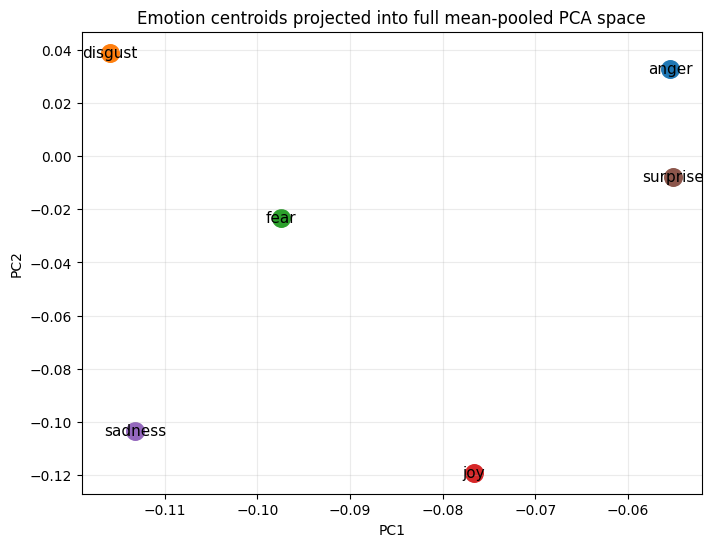


Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)
Explained variance ratio: [0.0854 0.0482 0.0396]


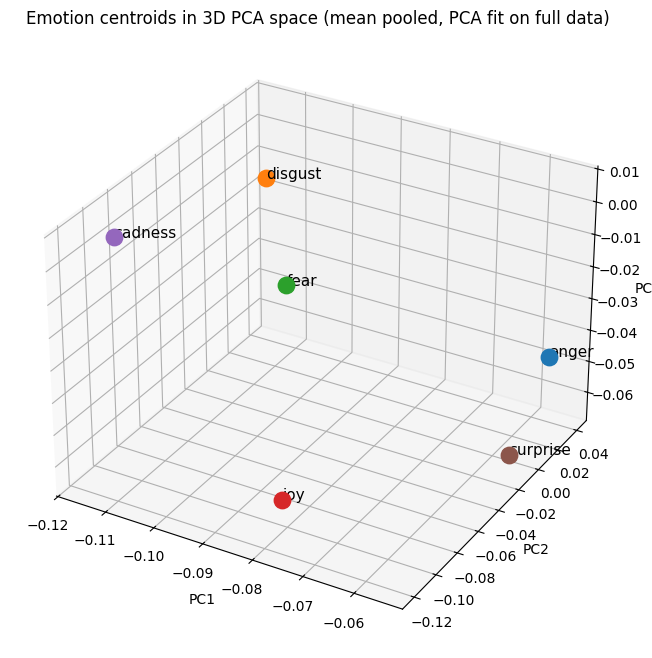


Emotion centroids projected into full CLS PCA space
Explained variance ratio: [0.1707 0.0766]


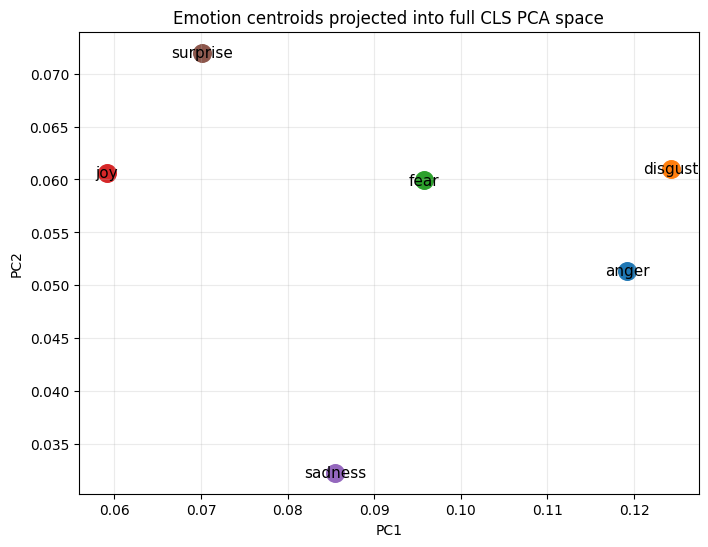

In [15]:
# mBERT visualizations

plot_centroids_in_full_pca_2d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids projected into full mean-pooled PCA space"
)

plot_centroids_in_full_pca_3d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)"
)

# Optional direct comparison with CLS
plot_centroids_in_full_pca_2d(
    cls_embeddings_norm,
    cls_centroids,
    emotion_order,
    "Emotion centroids projected into full CLS PCA space"
)


=== Mean-pooled probe ===
Accuracy: 0.3788
Balanced accuracy: 0.3788
Macro F1: 0.3696
Weighted F1: 0.3696
              precision    recall  f1-score   support

       anger      0.362     0.391     0.376      1000
     disgust      0.429     0.548     0.482      1000
        fear      0.265     0.164     0.202      1000
         joy      0.460     0.465     0.463      1000
     sadness      0.359     0.426     0.389      1000
    surprise      0.338     0.279     0.306      1000

    accuracy                          0.379      6000
   macro avg      0.369     0.379     0.370      6000
weighted avg      0.369     0.379     0.370      6000


=== CLS probe ===
Accuracy: 0.3703
Balanced accuracy: 0.3703
Macro F1: 0.3593
Weighted F1: 0.3593
              precision    recall  f1-score   support

       anger      0.349     0.396     0.371      1000
     disgust      0.399     0.514     0.449      1000
        fear      0.261     0.132     0.175      1000
         joy      0.453     0.462 

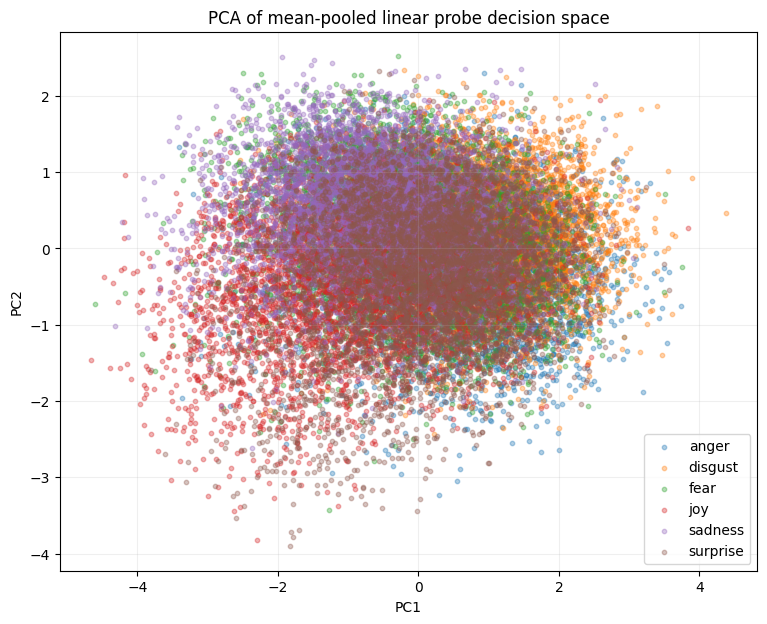


PCA of mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.3822 0.2366]


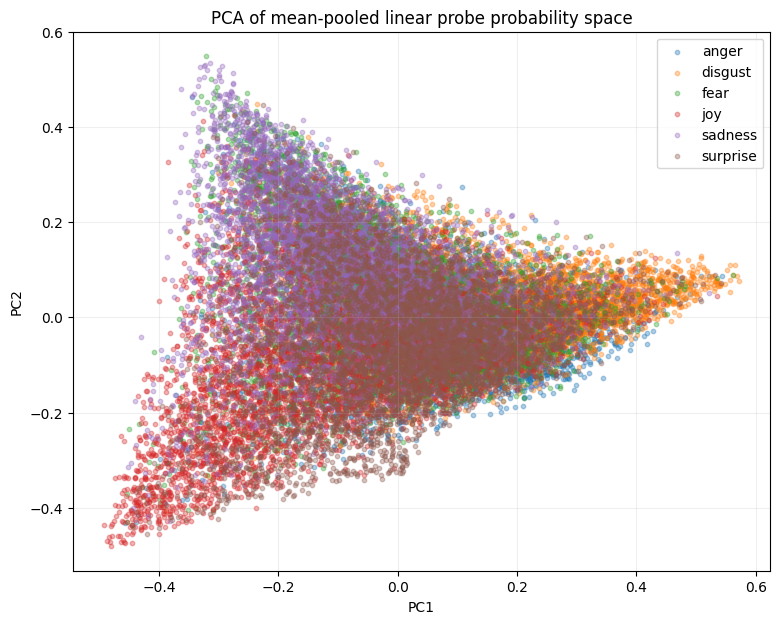


Emotion centroids in mean-pooled linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.4861 0.2321]


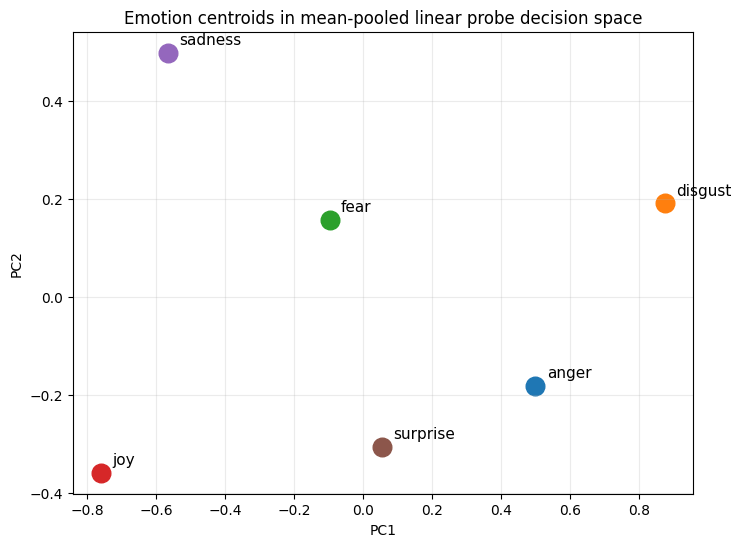


Emotion centroids in mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.3822 0.2366]


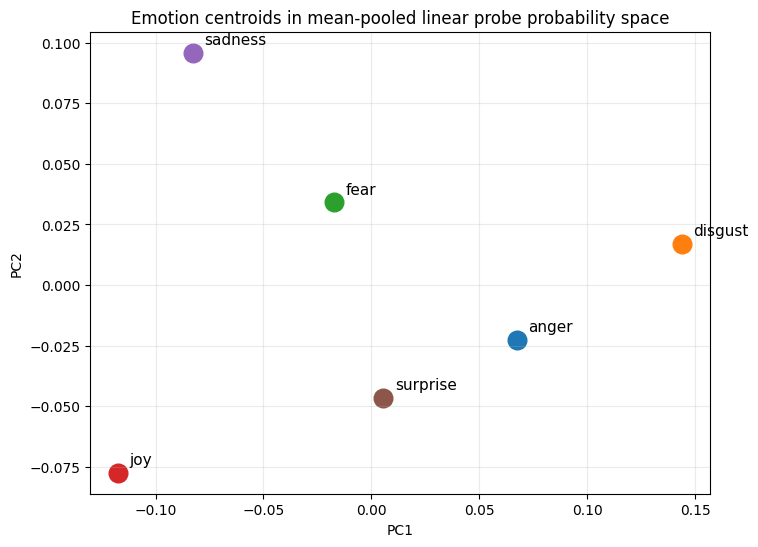


KDE contours of mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.3822 0.2366]


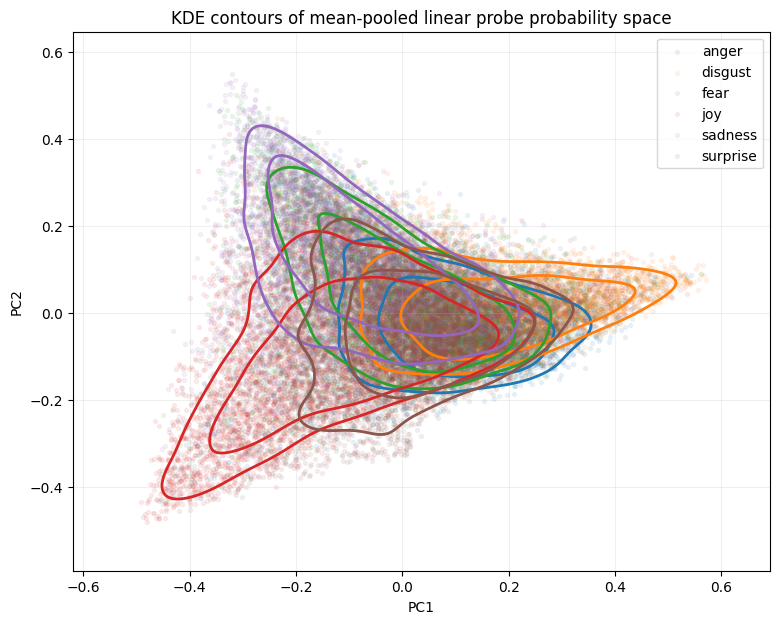


PCA of CLS linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.475 0.256]


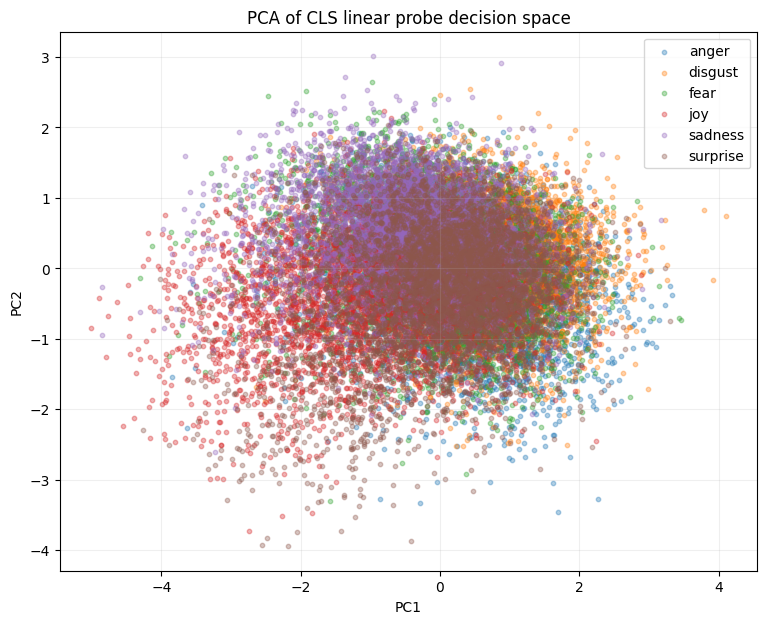


PCA of CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.382  0.2534]


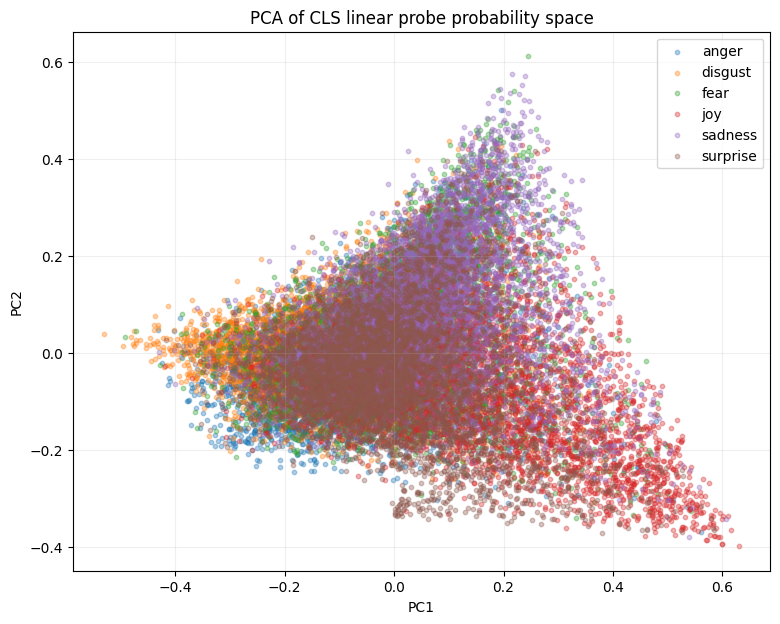


Emotion centroids in CLS linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.475 0.256]


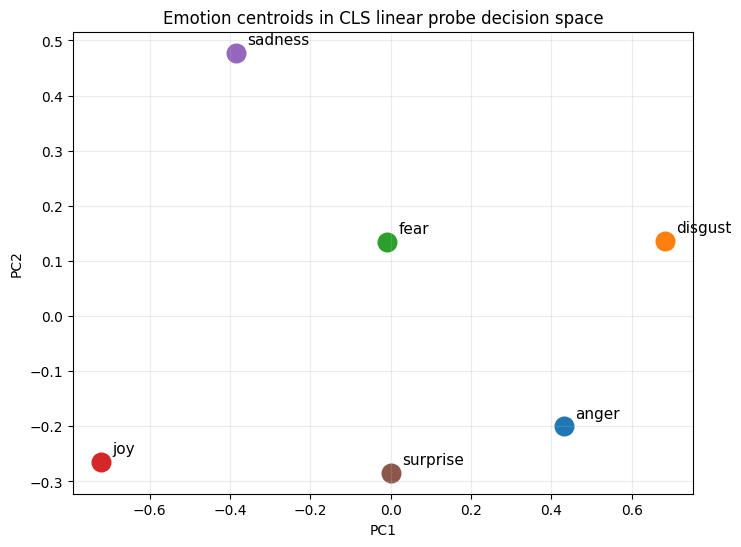


Emotion centroids in CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.382  0.2534]


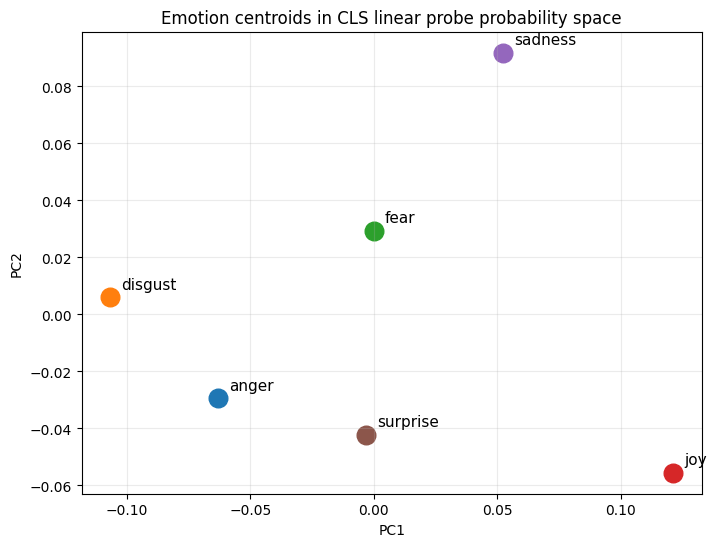


KDE contours of CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.382  0.2534]


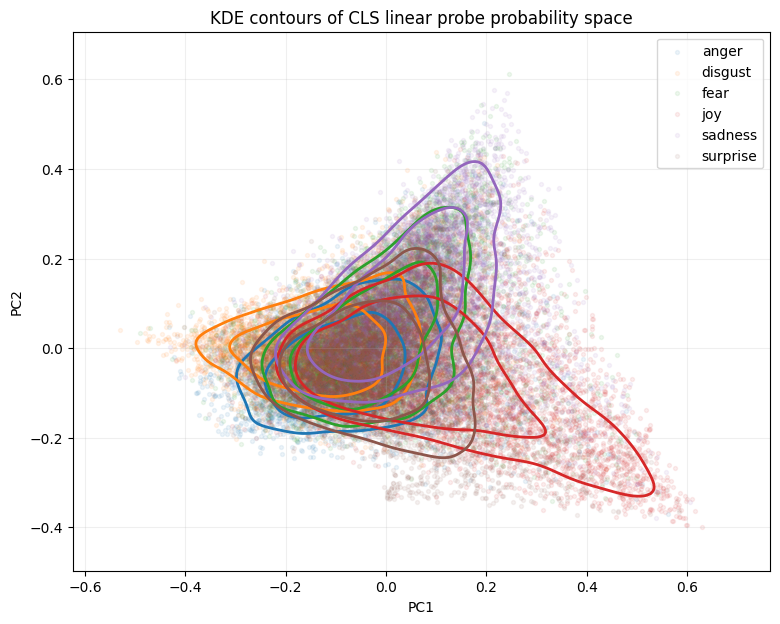

In [16]:
# probe training

mean_probe = train_probe(mean_embeddings_norm, labels, "Mean-pooled")
cls_probe = train_probe(cls_embeddings_norm, labels, "CLS")

# probe visualization

plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of mean-pooled linear probe probability space",
    use_probabilities=True
)

##### CLS!!!!!

# probe visualization

plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of CLS linear probe probability space",
    use_probabilities=True
)



Cosine similarity between mean-pooled probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000   -0.101 -0.164 -0.218   -0.246    -0.248
disgust  -0.101    1.000 -0.336 -0.325   -0.356    -0.175
fear     -0.164   -0.336  1.000 -0.262    0.231    -0.168
joy      -0.218   -0.325 -0.262  1.000   -0.158    -0.081
sadness  -0.246   -0.356  0.231 -0.158    1.000    -0.324
surprise -0.248   -0.175 -0.168 -0.081   -0.324     1.000


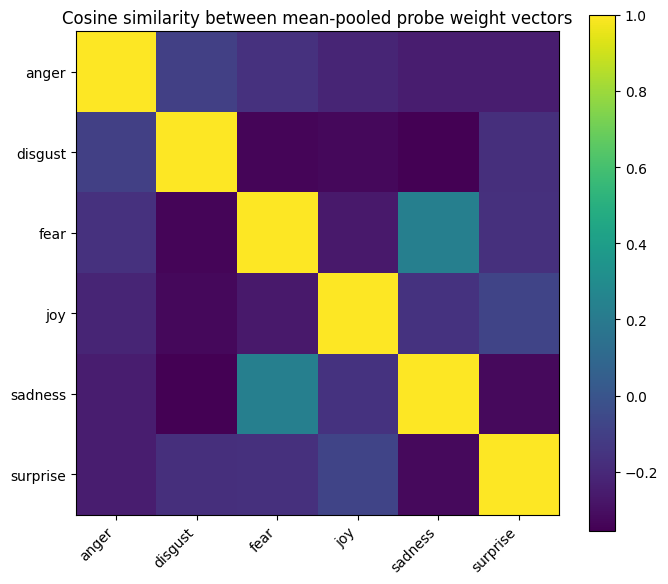


PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2806 0.232 ]


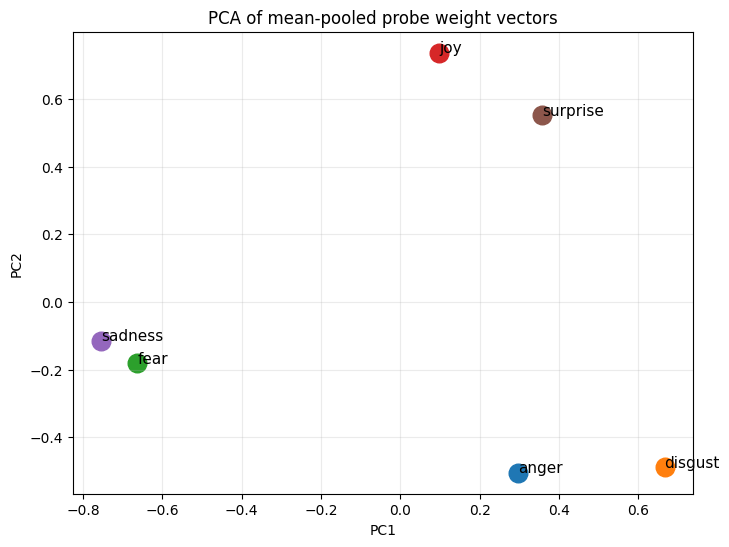


3D PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2806 0.232  0.1942]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
 0.2976 -0.5047 -0.5973    anger
 0.6661 -0.4880  0.3162  disgust
-0.6627 -0.1816  0.2686     fear
 0.0973  0.7368 -0.5575      joy
-0.7546 -0.1146  0.0034  sadness
 0.3564  0.5521  0.5666 surprise

Desmos-friendly format:
anger: (0.2976, -0.5047, -0.5973)
disgust: (0.6661, -0.4880, 0.3162)
fear: (-0.6627, -0.1816, 0.2686)
joy: (0.0973, 0.7368, -0.5575)
sadness: (-0.7546, -0.1146, 0.0034)
surprise: (0.3564, 0.5521, 0.5666)


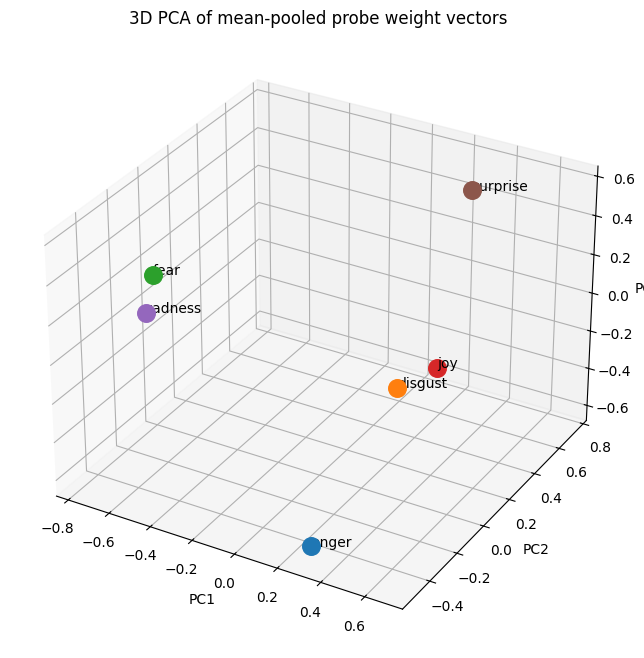


Mean-pooled probe weights vs mean-pooled class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.336  0.1849]


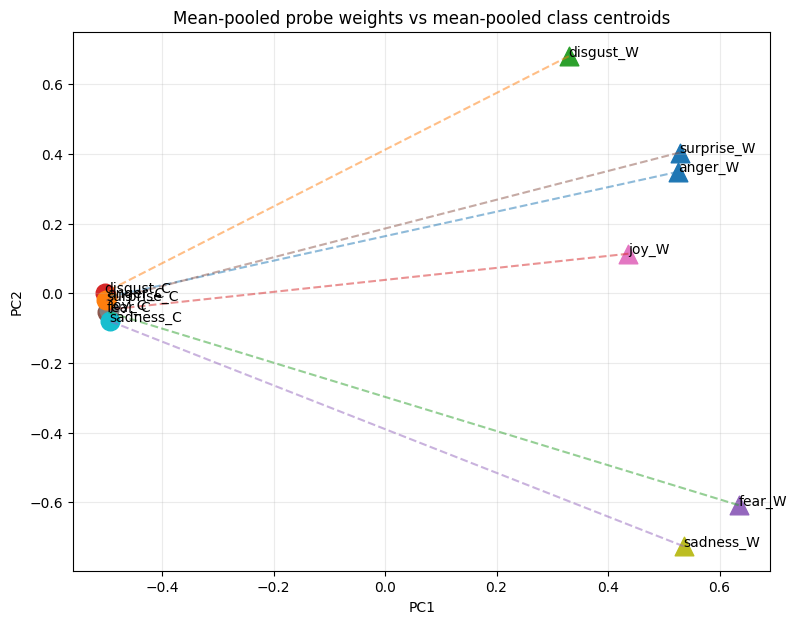


Cosine similarity between CLS probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000   -0.047 -0.196 -0.247   -0.260    -0.296
disgust  -0.047    1.000 -0.363 -0.349   -0.393    -0.148
fear     -0.196   -0.363  1.000 -0.215    0.234    -0.139
joy      -0.247   -0.349 -0.215  1.000   -0.146    -0.057
sadness  -0.260   -0.393  0.234 -0.146    1.000    -0.303
surprise -0.296   -0.148 -0.139 -0.057   -0.303     1.000


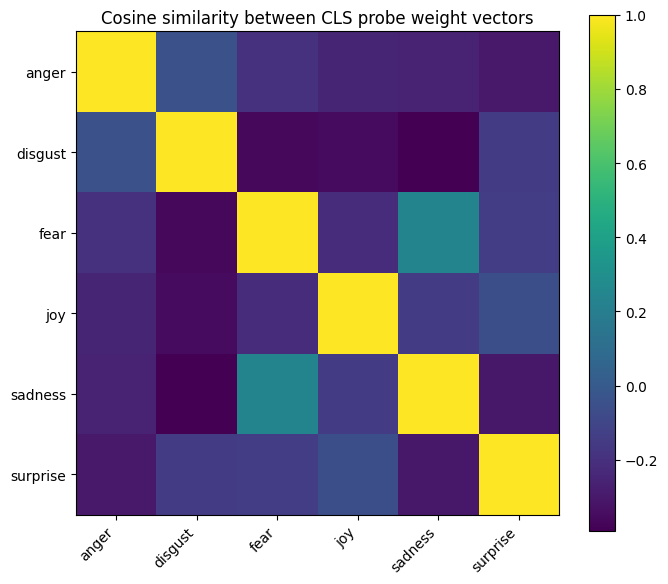


PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2904 0.2375]


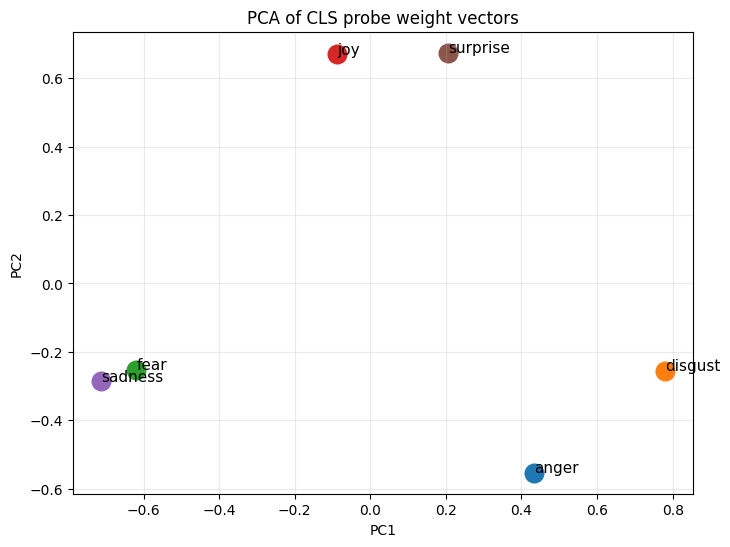


3D PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2904 0.2375 0.1928]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
 0.4343 -0.5529 -0.5031    anger
 0.7789 -0.2546  0.3378  disgust
-0.6186 -0.2522  0.3020     fear
-0.0881  0.6706 -0.6649      joy
-0.7123 -0.2848  0.0273  sadness
 0.2057  0.6740  0.5009 surprise

Desmos-friendly format:
anger: (0.4343, -0.5529, -0.5031)
disgust: (0.7789, -0.2546, 0.3378)
fear: (-0.6186, -0.2522, 0.3020)
joy: (-0.0881, 0.6706, -0.6649)
sadness: (-0.7123, -0.2848, 0.0273)
surprise: (0.2057, 0.6740, 0.5009)


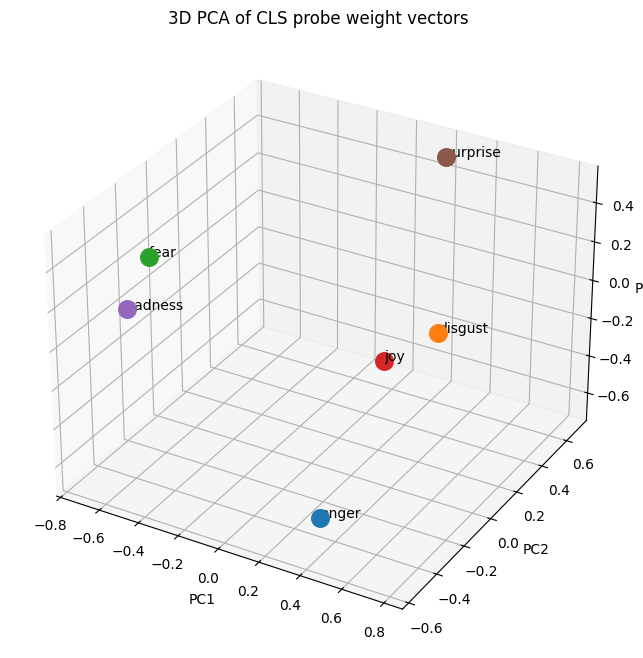


CLS probe weights vs CLS class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3337 0.193 ]


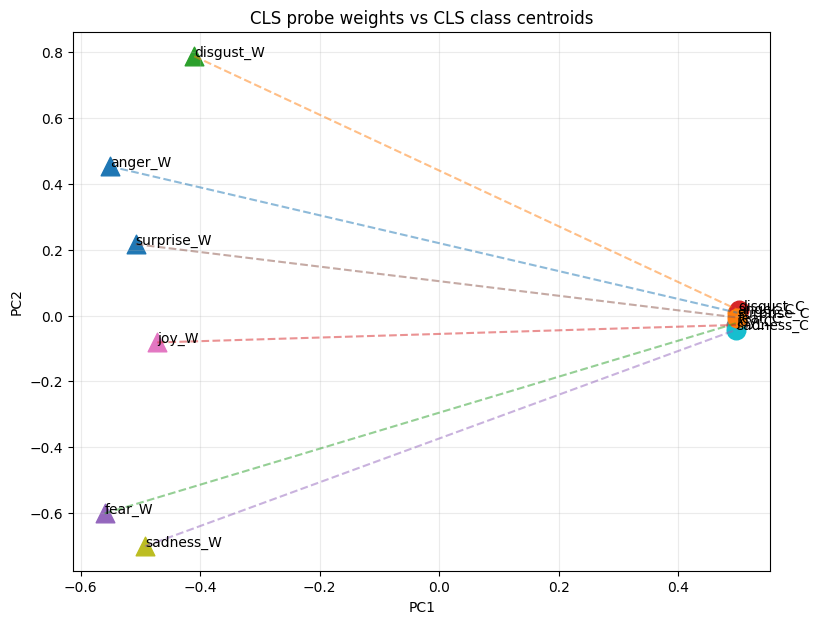

(array([[-0.55164124,  0.45356817],
        [-0.41013505,  0.78797959],
        [-0.56006346, -0.60137308],
        [-0.47185303, -0.08173778],
        [-0.49242741, -0.70085709],
        [-0.50789821,  0.21682286]]),
 array([[ 0.49914135,  0.00853441],
        [ 0.50138757,  0.01610159],
        [ 0.50003818, -0.02169182],
        [ 0.49681726, -0.0284996 ],
        [ 0.49759559, -0.04285174],
        [ 0.49903844, -0.00599553]]),
 PCA(n_components=2, random_state=42))

In [17]:

# Probe weight analysis

class_order = list(mean_probe.classes_)

# Mean-pooled probe weights
plot_probe_weight_cosine_similarity(
    mean_probe,
    class_order,
    "Cosine similarity between mean-pooled probe weight vectors"
)

plot_probe_weights_pca_2d(
    mean_probe,
    class_order,
    "PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_pca_3d(
    mean_probe,
    class_order,
    "3D PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    mean_probe,
    mean_centroids,
    class_order,
    "Mean-pooled probe weights vs mean-pooled class centroids"
)


# CLS probe weights
plot_probe_weight_cosine_similarity(
    cls_probe,
    class_order,
    "Cosine similarity between CLS probe weight vectors"
)

plot_probe_weights_pca_2d(
    cls_probe,
    class_order,
    "PCA of CLS probe weight vectors"
)

plot_probe_weights_pca_3d(
    cls_probe,
    class_order,
    "3D PCA of CLS probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    cls_probe,
    cls_centroids,
    class_order,
    "CLS probe weights vs CLS class centroids"
)

In [18]:
# example prediction and t-sne


print("\n--- Example predictions with mean-pooled probe ---")
predict_examples(example_texts, tokenizer, model, device, mean_probe, use_mean=True)

print("\n--- Example predictions with CLS probe ---")
predict_examples(example_texts, tokenizer, model, device, cls_probe, use_mean=False)

X_tsne_input = mean_embeddings_norm
y_tsne = df["emotion"].values


--- Example predictions with mean-pooled probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00,  2.41it/s]



TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.476), ('surprise', 0.262), ('fear', 0.129)]

TEXT: This is disgusting and makes me sick.
Predicted: disgust
Top-3: [('disgust', 0.305), ('sadness', 0.273), ('fear', 0.157)]

TEXT: I am terrified something bad will happen.
Predicted: sadness
Top-3: [('sadness', 0.42), ('fear', 0.29), ('surprise', 0.101)]

TEXT: I miss you so much and feel empty.
Predicted: sadness
Top-3: [('sadness', 0.595), ('joy', 0.157), ('fear', 0.125)]

TEXT: What a wonderful surprise!
Predicted: surprise
Top-3: [('surprise', 0.553), ('joy', 0.37), ('fear', 0.041)]

TEXT: I am furious and cannot stand this anymore.
Predicted: sadness
Top-3: [('sadness', 0.535), ('fear', 0.171), ('joy', 0.116)]

--- Example predictions with CLS probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00, 49.16it/s]


TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.537), ('surprise', 0.203), ('sadness', 0.12)]

TEXT: This is disgusting and makes me sick.
Predicted: sadness
Top-3: [('sadness', 0.435), ('disgust', 0.193), ('fear', 0.165)]

TEXT: I am terrified something bad will happen.
Predicted: sadness
Top-3: [('sadness', 0.393), ('fear', 0.265), ('joy', 0.1)]

TEXT: I miss you so much and feel empty.
Predicted: sadness
Top-3: [('sadness', 0.526), ('joy', 0.157), ('fear', 0.145)]

TEXT: What a wonderful surprise!
Predicted: joy
Top-3: [('joy', 0.474), ('surprise', 0.463), ('fear', 0.033)]

TEXT: I am furious and cannot stand this anymore.
Predicted: sadness
Top-3: [('sadness', 0.584), ('fear', 0.177), ('joy', 0.098)]


In [19]:
from datasets import load_dataset
import pandas as pd

target_emotions = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
random_state = 42

# =====================================================
# 1. LOAD BRIGHTER
# =====================================================
dfs = []

for split in ["train", "dev", "test"]:
    ds = load_dataset(
        "brighter-dataset/BRIGHTER-emotion-categories",
        "eng",
        split=split
    )
    df_part = ds.to_pandas()
    dfs.append(df_part)

brighter_df = pd.concat(dfs, ignore_index=True)
brighter_df["text"] = brighter_df["text"].astype(str)

# ensure all emotion columns exist + clean
for col in target_emotions:
    if col not in brighter_df.columns:
        brighter_df[col] = 0
    brighter_df[col] = brighter_df[col].fillna(0).astype(int)

# keep only single-label
brighter_df["n_active"] = brighter_df[target_emotions].sum(axis=1)
brighter_df = brighter_df[brighter_df["n_active"] == 1].copy()

# convert to single label
brighter_df["emotion"] = brighter_df[target_emotions].idxmax(axis=1)

brighter_df = brighter_df[["text", "emotion"]]

print("\nBRIGHTER distribution:")
print(brighter_df["emotion"].value_counts())


# # =====================================================
# # 2. LOAD GOEMOTIONS (your CSV)
# # =====================================================
# go_df = pd.read_csv("goemotions_english.csv")

# go_df["text"] = go_df["text"].astype(str)
# go_df["emotion"] = go_df["emotion"].astype(str)

# # keep only target emotions (important!)
# go_df = go_df[go_df["emotion"].isin(target_emotions)]

# print("\nGoEmotions distribution:")
# print(go_df["emotion"].value_counts())


# =====================================================
# 2.1 LOAD XED (your CSV)
# =====================================================
xed_df = pd.read_csv("xed_english.csv")

xed_df["text"] = xed_df["text"].astype(str)
xed_df["emotion"] = xed_df["emotion"].astype(str)

# keep only target emotions (important!)
xed_df = xed_df[xed_df["emotion"].isin(target_emotions)]

print("\XED distribution:")
print(xed_df["emotion"].value_counts())


# =====================================================
# 3. COMBINE
# =====================================================
comb_df = pd.concat([brighter_df, xed_df], ignore_index=True)

print("\nCombined distribution BEFORE balancing:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 4. BALANCE
# =====================================================
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []

for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced rows:", len(comb_df))
print("\nBalanced distribution:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 5. FINAL OUTPUT
# =====================================================
xed_texts = comb_df["text"].tolist()
xed_labels = comb_df["emotion"].tolist()


xed_mean_embeddings, xed_cls_embeddings = encode_texts(
    xed_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

xed_mean_embeddings_norm = normalize(xed_mean_embeddings, norm="l2")
xed_cls_embeddings_norm = normalize(xed_cls_embeddings, norm="l2")

print("\nXED mean embeddings shape:", xed_mean_embeddings_norm.shape)
print("XED CLS embeddings shape:", xed_cls_embeddings_norm.shape)

print("\nMean probe classes:", mean_probe.classes_)
print("CLS probe classes:", cls_probe.classes_)

class_order = list(mean_probe.classes_)

# Split df into calibration and test
mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    xed_mean_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    xed_cls_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)



print("\nCalibration set size:", len(y_calib))
print("Test set size:", len(y_test))


# Evaluation stats
def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in gold_labels])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }


# Baseline: uncalibrated
mean_base_results = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled mBERT (uncalibrated)"
)


BRIGHTER distribution:
emotion
joy         1350
fear        1134
sadness      401
surprise     335
anger        198
Name: count, dtype: int64
\XED distribution:
emotion
anger       2391
joy         1721
fear        1529
sadness     1527
surprise    1429
disgust     1413
Name: count, dtype: int64

Combined distribution BEFORE balancing:
emotion
joy         3071
fear        2663
anger       2589
sadness     1928
surprise    1764
disgust     1413
Name: count, dtype: int64

Balanced rows: 8478

Balanced distribution:
emotion
anger       1413
surprise    1413
fear        1413
joy         1413
sadness     1413
disgust     1413
Name: count, dtype: int64


Encoding: 100%|██████████| 265/265 [00:56<00:00,  4.72it/s]


XED mean embeddings shape: (8478, 768)
XED CLS embeddings shape: (8478, 768)

Mean probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']
CLS probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']

Calibration set size: 4239
Test set size: 4239

=== Mean-pooled mBERT (uncalibrated) on XED test ===
Accuracy: 0.348
Balanced accuracy: 0.3479
Macro F1: 0.3399
Weighted F1: 0.3399
Log loss: 1.6273
Top-3 accuracy: 0.7056

Classification report:
              precision    recall  f1-score   support

       anger      0.323     0.259     0.288       706
     disgust      0.320     0.248     0.279       706
        fear      0.312     0.291     0.301       707
         joy      0.383     0.279     0.322       707
     sadness      0.357     0.536     0.429       707
    surprise      0.377     0.475     0.420       706

    accuracy                          0.348      4239
   macro avg      0.345     0.348     0.340      4239
weighted avg      0.345     0.348     0.3

In [20]:
# =====================================================
# HUMAN-LABEL FINE-TUNED PROBE
# =====================================================

from sklearn.linear_model import LogisticRegression

def train_eval_human_probe(X_calib, X_test, y_calib, y_test, class_order, name):
    human_probe = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    human_probe.fit(X_calib, y_calib)

    preds = human_probe.predict(X_test)
    probs = human_probe.predict_proba(X_test)

    print(f"\n=== {name}: probe trained on human calibration data ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    top_k = 3
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])
    top_k_acc = np.mean([gold_idx[i] in top_k_preds[i] for i in range(len(gold_idx))])
    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": human_probe,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_human_probe_results = train_eval_human_probe(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled"
)

cls_human_probe_results = train_eval_human_probe(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    class_order,
    name="CLS"
)


=== Mean-pooled: probe trained on human calibration data ===
Accuracy: 0.4902
Balanced accuracy: 0.4902
Macro F1: 0.4888
Weighted F1: 0.4888
Log loss: 1.3444
Top-3 accuracy: 0.8398

Classification report:
              precision    recall  f1-score   support

       anger      0.431     0.442     0.436       706
     disgust      0.472     0.486     0.479       706
        fear      0.492     0.406     0.445       707
         joy      0.555     0.610     0.581       707
     sadness      0.476     0.471     0.474       707
    surprise      0.510     0.527     0.518       706

    accuracy                          0.490      4239
   macro avg      0.489     0.490     0.489      4239
weighted avg      0.489     0.490     0.489      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       312      124    53   52       69        96
disgust     128      343    24   53       81        77
fear        103       67   287   77       93        80
joy          

In [21]:
from sklearn.linear_model import LogisticRegression

# =====================================================
# 6D EMOTION SUBSPACE CLASSIFIER
# =====================================================

def project_to_probe_subspace(X, probe, use_bias=False):
    W = probe.coef_.copy()
    Z = X @ W.T

    if use_bias:
        Z = Z + probe.intercept_

    return Z


def train_eval_6d_classifier(X_calib, X_test, y_calib, y_test, probe, class_order, name, use_bias=False):
    Z_calib = project_to_probe_subspace(X_calib, probe, use_bias=use_bias)
    Z_test = project_to_probe_subspace(X_test, probe, use_bias=use_bias)

    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: Logistic Regression on 6D probe subspace ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "Z_calib": Z_calib,
        "Z_test": Z_test,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_6d_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_probe,
    class_order,
    name="Mean-pooled"
)

cls_6d_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_probe,
    class_order,
    name="CLS"
)


=== Mean-pooled: Logistic Regression on 6D probe subspace ===
6D train shape: (4239, 6)
6D test shape: (4239, 6)
Accuracy: 0.3744
Balanced accuracy: 0.3744
Macro F1: 0.3715
Weighted F1: 0.3715
Log loss: 1.5486

Classification report:
              precision    recall  f1-score   support

       anger      0.353     0.283     0.314       706
     disgust      0.354     0.361     0.358       706
        fear      0.344     0.296     0.318       707
         joy      0.393     0.403     0.398       707
     sadness      0.386     0.472     0.425       707
    surprise      0.404     0.431     0.417       706

    accuracy                          0.374      4239
   macro avg      0.372     0.374     0.372      4239
weighted avg      0.372     0.374     0.372      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       200      133    92   92       91        98
disgust      97      255    76  105       94        79
fear         94       79   209   72    

In [22]:
mean_6d_human_probe_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_human_probe_results["model"],
    class_order,
    name="Mean-pooled human-probe 6D"
)

cls_6d_human_probe_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_human_probe_results["model"],
    class_order,
    name="CLS human-probe 6D"
)


=== Mean-pooled human-probe 6D: Logistic Regression on 6D probe subspace ===
6D train shape: (4239, 6)
6D test shape: (4239, 6)
Accuracy: 0.4954
Balanced accuracy: 0.4954
Macro F1: 0.4946
Weighted F1: 0.4946
Log loss: 1.3363

Classification report:
              precision    recall  f1-score   support

       anger      0.433     0.441     0.436       706
     disgust      0.487     0.497     0.492       706
        fear      0.489     0.436     0.461       707
         joy      0.568     0.605     0.586       707
     sadness      0.478     0.468     0.473       707
    surprise      0.512     0.525     0.519       706

    accuracy                          0.495      4239
   macro avg      0.495     0.495     0.495      4239
weighted avg      0.495     0.495     0.495      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       311      120    64   49       72        90
disgust     132      351    30   46       74        73
fear         94       58

In [23]:
# =====================================================
# LABEL DISAGREEMENT / ERROR INSPECTION
# =====================================================

# Recreate split with indices so we can recover the original texts
all_indices = np.arange(len(comb_df))

mean_idx_calib, mean_idx_test, _, _ = train_test_split(
    all_indices,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

test_texts = comb_df.iloc[mean_idx_test]["text"].tolist()
test_gold = np.array(y_test)

def inspect_strong_disagreements(X_test, probe, test_texts, gold_labels, class_order, n=30, name="Probe"):
    probs = probe.predict_proba(X_test)
    preds = probe.predict(X_test)

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    rows = []

    for i in range(len(gold_labels)):
        if preds[i] != gold_labels[i]:
            top3_idx = np.argsort(probs[i])[::-1][:3]
            top3 = [(class_order[j], round(float(probs[i, j]), 3)) for j in top3_idx]

            rows.append({
                "text": test_texts[i],
                "gold": gold_labels[i],
                "pred": preds[i],
                "confidence": pred_conf[i],
                "top3": top3
            })

    err_df = pd.DataFrame(rows).sort_values("confidence", ascending=False)

    print(f"\n=== Strongest disagreements: {name} ===")
    print("Total errors:", len(err_df))

    for _, row in err_df.head(n).iterrows():
        print("\nTEXT:", row["text"])
        print("Gold:", row["gold"])
        print("Pred:", row["pred"])
        print("Confidence:", round(row["confidence"], 4))
        print("Top-3:", row["top3"])

    return err_df


mean_error_df = inspect_strong_disagreements(
    mean_X_test,
    mean_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="Mean-pooled probe"
)

cls_error_df = inspect_strong_disagreements(
    cls_X_test,
    cls_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="CLS probe"
)


=== Strongest disagreements: Mean-pooled probe ===
Total errors: 2764

TEXT: Happy birthday .
Gold: joy
Pred: surprise
Confidence: 0.8688
Top-3: [('surprise', 0.869), ('sadness', 0.044), ('fear', 0.041)]

TEXT: quite the opposite, it took literally 4 shots worth of liquor to make him stinking, piss/shit in pants drunk.
Gold: surprise
Pred: disgust
Confidence: 0.7469
Top-3: [('disgust', 0.747), ('anger', 0.093), ('surprise', 0.062)]

TEXT: Maybe we've missed him already .
Gold: fear
Pred: sadness
Confidence: 0.7466
Top-3: [('sadness', 0.747), ('fear', 0.094), ('surprise', 0.06)]

TEXT: You're good , but you're taking on a lot .
Gold: sadness
Pred: joy
Confidence: 0.7379
Top-3: [('joy', 0.738), ('sadness', 0.096), ('surprise', 0.083)]

TEXT: Isabel , you look very lovely tonight .
Gold: surprise
Pred: joy
Confidence: 0.7245
Top-3: [('joy', 0.724), ('surprise', 0.129), ('sadness', 0.076)]

TEXT: More fun and games ?
Gold: anger
Pred: surprise
Confidence: 0.7191
Top-3: [('surprise', 0.719

In [24]:

# Projection classifier: cosine to probe weights

mean_weight_preds, mean_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_weight_results = evaluate_simple_classifier(
    y_test,
    mean_weight_preds,
    mean_weight_scores,
    class_order,
    name="Mean-pooled XLM-R (cosine to probe weights)"
)

cls_weight_preds, cls_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_weight_results = evaluate_simple_classifier(
    y_test,
    cls_weight_preds,
    cls_weight_scores,
    class_order,
    name="CLS XLM-R (cosine to probe weights)"
)


# Prototype classifier: nearest centroid

mean_proto_preds, mean_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proto_preds,
    mean_proto_scores,
    class_order,
    name="Mean-pooled XLM-R (prototype classifier)"
)

cls_proto_preds, cls_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proto_preds,
    cls_proto_scores,
    class_order,
    name="CLS XLM-R (prototype classifier)"
)




=== Mean-pooled XLM-R (cosine to probe weights) on XED test ===
Accuracy: 0.3298
Balanced accuracy: 0.3298
Macro F1: 0.3014
Weighted F1: 0.3014
Log loss: 1.7672

Classification report:
              precision    recall  f1-score   support

       anger      0.392     0.132     0.197       706
     disgust      0.276     0.494     0.354       706
        fear      0.402     0.099     0.159       707
         joy      0.330     0.388     0.357       707
     sadness      0.320     0.632     0.425       707
    surprise      0.494     0.234     0.317       706

    accuracy                          0.330      4239
   macro avg      0.369     0.330     0.301      4239
weighted avg      0.369     0.330     0.301      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        93      163    26  192      184        48
disgust      51      349    12  119      152        23
fear         40      176    70   82      295        44
joy          11      200    14  2

In [25]:
### TEST

example_texts = [
    "I just got promoted at work, I can't believe it!",
    "This is absolutely disgusting, I feel sick.",
    "I'm really scared about what might happen tomorrow.",
    "I miss you so much, everything feels empty without you.",
    "Wow, I did not expect that at all!"
]

def print_topk_linear_predictions(
    texts,
    tokenizer,
    model,
    device,
    probe,
    class_order,
    use_mean=True,
    top_k=3
):
    # Encode
    mean_embs, cls_embs = encode_texts(
        texts,
        tokenizer,
        model,
        device,
        batch_size=8,
        max_length=MAX_LENGTH
    )

    if use_mean:
        X = normalize(mean_embs, norm="l2")
    else:
        X = normalize(cls_embs, norm="l2")

    # Get linear scores
    _, scores = predict_with_linear_scores(
        X,
        probe,
        class_order,
        normalize_inputs=False
    )

    print("\n=== Top-k predictions (linear scores x·w + b) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
    _, scores = predict_with_weight_cosine(
        X,
        probe,
        class_order
    )

    print("\n=== Top-k predictions (just linear scores x·w) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
print_topk_linear_predictions(
    example_texts,
    tokenizer,
    model,
    device,
    mean_probe,
    class_order,
    use_mean=True
)

Encoding: 100%|██████████| 1/1 [00:00<00:00,  1.55it/s]


=== Top-k predictions (linear scores x·w + b) ===

Text: I just got promoted at work, I can't believe it!
  1. fear       | score = 0.8691
  2. sadness    | score = 0.4519
  3. anger      | score = 0.1242

Text: This is absolutely disgusting, I feel sick.
  1. sadness    | score = 0.9085
  2. disgust    | score = 0.6179
  3. fear       | score = 0.5777

Text: I'm really scared about what might happen tomorrow.
  1. sadness    | score = 1.5315
  2. fear       | score = 1.0148
  3. surprise   | score = 0.1515

Text: I miss you so much, everything feels empty without you.
  1. sadness    | score = 1.6739
  2. joy        | score = 1.4406
  3. fear       | score = -0.0493

Text: Wow, I did not expect that at all!
  1. fear       | score = 0.5350
  2. surprise   | score = 0.4906
  3. joy        | score = -0.0600


=== Top-k predictions (just linear scores x·w) ===

Text: I just got promoted at work, I can't believe it!
  1. sadness    | score = 0.0454
  2. fear       | score = 0.0363
  3. j

In [26]:
def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


# Human-labeled English centroids

mean_human_centroids = compute_label_centroids(
    mean_X_calib,
    y_calib,
    class_order
)

# CHINESE

In [27]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_chinese.csv", "xed_tw.csv", "brighter_chinese.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 5426

Original German class distribution:
emotion
anger       2144
joy         1732
sadness      830
surprise     311
disgust      208
fear         201
Name: count, dtype: int64

Balanced German rows: 1206

Balanced German class distribution:
emotion
anger       201
disgust     201
joy         201
fear        201
sadness     201
surprise    201
Name: count, dtype: int64


Encoding: 100%|██████████| 38/38 [00:24<00:00,  1.57it/s]


German mean embeddings shape: (1206, 768)
German CLS embeddings shape: (1206, 768)

German calibration set size: 603
German test set size: 603


In [28]:

# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np

def fit_bias_only(
    X_calib,
    y_calib,
    probe,
    class_order,
    l2_values=(0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0),
    random_state=42,
):
    """
    Freeze probe weights W, tune L2 regularization, and learn only bias b.
    L2 is selected using an internal split of the calibration set.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}

    X_train, X_val, y_train, y_val = train_test_split(
        X_calib,
        y_calib,
        test_size=0.3,
        random_state=random_state,
        stratify=y_calib,
    )

    y_train_idx = np.array([label_to_idx[y] for y in y_train])

    def softmax_np(scores):
        scores = scores - scores.max(axis=1, keepdims=True)
        exp_scores = np.exp(scores)
        return exp_scores / exp_scores.sum(axis=1, keepdims=True)

    def fit_for_l2(l2):
        def objective(b):
            scores = X_train @ W.T + b
            probs = softmax_np(scores)

            nll = -np.mean(
                np.log(probs[np.arange(len(y_train_idx)), y_train_idx] + 1e-12)
            )

            penalty = l2 * np.sum((b - old_b) ** 2)

            return nll + penalty

        result = minimize(
            objective,
            x0=old_b,
            method="BFGS",
        )

        return result.x

    best_l2 = None
    best_f1 = -1
    best_b = None

    print("\nBias-only calibration L2 search:")

    for l2 in l2_values:
        candidate_b = fit_for_l2(l2)

        val_scores = X_val @ W.T + candidate_b
        val_pred_idx = np.argmax(val_scores, axis=1)
        val_preds = np.array([class_order[i] for i in val_pred_idx])

        val_f1 = f1_score(y_val, val_preds, average="macro")

        print(f"  l2={l2:<8} validation_macro_f1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_l2 = l2
            best_b = candidate_b

    print(f"Best l2: {best_l2} | validation_macro_f1={best_f1:.4f}")

    # Refit final bias on the full calibration set using best L2
    y_calib_idx = np.array([label_to_idx[y] for y in y_calib])

    def final_objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(
            np.log(probs[np.arange(len(y_calib_idx)), y_calib_idx] + 1e-12)
        )

        penalty = best_l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    final_result = minimize(
        final_objective,
        x0=old_b,
        method="BFGS",
    )

    return final_result.x


def evaluate_fixed_weights_new_bias(X_test, y_test, probe, new_b, class_order, name):
    W = probe.coef_.copy()
    scores = X_test @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


def fit_procrustes_from_centroids(X_calib, y_calib, target_centroids, class_order):
    """
    Learns an orthogonal rotation from German calibration centroids
    to English weak-label centroids.
    """
    source_centroids = compute_label_centroids(X_calib, y_calib, class_order)

    R, scale = orthogonal_procrustes(source_centroids, target_centroids)

    print("\nProcrustes scale:", round(scale, 4))

    return R


def apply_rotation(X, R):
    return normalize(X @ R, norm="l2")

In [29]:
from sklearn.linear_model import LogisticRegression

def project_to_probe_subspace(X, probe):
    """
    Projects embeddings into the 6D English probe-weight emotion space:
        Z = X @ W.T
    """
    W = probe.coef_.copy()
    return X @ W.T


def evaluate_6d_logreg(Z_calib, Z_test, y_calib, y_test, class_order, name):
    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: LogReg on 6D projected emotion space ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }

In [30]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.3068
Balanced accuracy: 0.3071
Macro F1: 0.2868
Weighted F1: 0.2868
Log loss: 1.7362

Classification report:
              precision    recall  f1-score   support

       anger      0.294     0.630     0.401       100
     disgust      0.435     0.100     0.163       100
        fear      0.274     0.228     0.249       101
         joy      0.613     0.376     0.466       101
     sadness      0.229     0.109     0.148       101
    surprise      0.233     0.400     0.294       100

    accuracy                          0.307       603
   macro avg      0.346     0.307     0.287       603
weighted avg      0.346     0.307     0.287       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        63        0    12    3        1        21
disgust      37       10    15    5       14        19
fear         43        4    23    4       10        17
joy          16        3     6   38        1

# ESTONIAN

In [31]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_estonian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
# target_n = comb_df["emotion"].value_counts().min()
target_n = 20

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 674

Original German class distribution:
emotion
anger       205
fear        106
joy         105
surprise    102
sadness     101
disgust      55
Name: count, dtype: int64

Balanced German rows: 120

Balanced German class distribution:
emotion
fear        20
anger       20
disgust     20
joy         20
surprise    20
sadness     20
Name: count, dtype: int64


Encoding: 100%|██████████| 4/4 [00:00<00:00,  6.74it/s]


German mean embeddings shape: (120, 768)
German CLS embeddings shape: (120, 768)

German calibration set size: 60
German test set size: 60


In [32]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.25
Balanced accuracy: 0.25
Macro F1: 0.2171
Weighted F1: 0.2171
Log loss: 1.8697

Classification report:
              precision    recall  f1-score   support

       anger      0.231     0.600     0.333        10
     disgust      0.500     0.300     0.375        10
        fear      0.231     0.300     0.261        10
         joy      0.200     0.100     0.133        10
     sadness      0.000     0.000     0.000        10
    surprise      0.200     0.200     0.200        10

    accuracy                          0.250        60
   macro avg      0.227     0.250     0.217        60
weighted avg      0.227     0.250     0.217        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         6        0     2    1        0         1
disgust       4        3     1    0        0         2
fear          5        0     3    1        0         1
joy           3        1     2    1        0    

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


 0.2172
Log loss: 1.7837

Classification report:
              precision    recall  f1-score   support

       anger      0.375     0.300     0.333        10
     disgust      0.364     0.400     0.381        10
        fear      0.000     0.000     0.000        10
         joy      0.105     0.200     0.138        10
     sadness      0.375     0.300     0.333        10
    surprise      0.143     0.100     0.118        10

    accuracy                          0.217        60
   macro avg      0.227     0.217     0.217        60
weighted avg      0.227     0.217     0.217        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         3        0     1    5        0         1
disgust       2        4     0    3        0         1
fear          1        2     0    3        3         1
joy           1        1     1    2        2         3
sadness       1        2     2    2        3         0
surprise      0        2     3    4        0         1

=== 

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9791

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2
Balanced accuracy: 0.2
Macro F1: 0.1901
Weighted F1: 0.1901
Log loss: 1.8559

Classification report:
              precision    recall  f1-score   support

       anger      0.267     0.400     0.320        10
     disgust      0.214     0.300     0.250        10
        fear      0.286     0.200     0.235        10
         joy      0.143     0.100     0.118        10
     sadness      0.100     0.100     0.100        10
    surprise      0.143     0.100     0.118        10

    accuracy                          0.200        60
   macro avg      0.192     0.200     0.190        60
weighted avg      0.192     0.200     0.190        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         4        3     1    0        1         1
disgust       2        3     0    2        1         2
fear          2        1     2    1        3         1
joy           

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0      validation_macro_f1=0.8119
  l2=0.0001   validation_macro_f1=0.8119
  l2=0.001    validation_macro_f1=0.8119
  l2=0.01     validation_macro_f1=0.7381
  l2=0.1      validation_macro_f1=0.7440
  l2=1.0      validation_macro_f1=0.7440
Best l2: 0.0 | validation_macro_f1=0.8119

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.2
Balanced accuracy: 0.2
Macro F1: 0.1871
Weighted F1: 0.1871
Log loss: 1.8557

Classification report:
              precision    recall  f1-score   support

       anger      0.333     0.400     0.364        10
     disgust      0.100     0.100     0.100        10
        fear      0.375     0.300     0.333        10
         joy      0.000     0.000     0.000        10
     sadness      0.167     0.300     0.214        10
    surprise      0.125     0.100     0.111        10

    accuracy                          0.200        60
   macro avg      0.183     0.200     0.187        60
weighted avg      0.183     0.200     0.187    

# RUSSIAN

In [33]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_russian.csv", "brighter_russian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 4540

Original German class distribution:
emotion
anger       1043
joy         1015
fear         734
sadness      724
surprise     612
disgust      412
Name: count, dtype: int64

Balanced German rows: 2472

Balanced German class distribution:
emotion
fear        412
surprise    412
sadness     412
joy         412
anger       412
disgust     412
Name: count, dtype: int64


Encoding: 100%|██████████| 78/78 [00:22<00:00,  3.49it/s]


German mean embeddings shape: (2472, 768)
German CLS embeddings shape: (2472, 768)

German calibration set size: 1236
German test set size: 1236


In [34]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.254
Balanced accuracy: 0.254
Macro F1: 0.2189
Weighted F1: 0.2189
Log loss: 1.802

Classification report:
              precision    recall  f1-score   support

       anger      0.214     0.568     0.311       206
     disgust      0.407     0.243     0.304       206
        fear      0.245     0.112     0.153       206
         joy      0.190     0.073     0.105       206
     sadness      0.185     0.049     0.077       206
    surprise      0.291     0.481     0.363       206

    accuracy                          0.254      1236
   macro avg      0.255     0.254     0.219      1236
weighted avg      0.255     0.254     0.219      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       117       13    10   12        8        46
disgust     100       50    10   15        7        24
fear         97       11    23   19       23        33
joy          83       14    13   15        3   

# SWAHILI

In [35]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_swahili.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3965

Original German class distribution:
emotion
surprise    1103
joy          951
sadness      675
anger        623
disgust      434
fear         179
Name: count, dtype: int64

Balanced German rows: 1074

Balanced German class distribution:
emotion
joy         179
fear        179
disgust     179
surprise    179
anger       179
sadness     179
Name: count, dtype: int64


Encoding: 100%|██████████| 34/34 [00:09<00:00,  3.48it/s]


German mean embeddings shape: (1074, 768)
German CLS embeddings shape: (1074, 768)

German calibration set size: 537
German test set size: 537


In [36]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1993
Balanced accuracy: 0.2
Macro F1: 0.1444
Weighted F1: 0.144
Log loss: 1.9319

Classification report:
              precision    recall  f1-score   support

       anger      0.181     0.449     0.258        89
     disgust      0.400     0.022     0.043        89
        fear      0.182     0.067     0.098        90
         joy      0.154     0.133     0.143        90
     sadness      0.000     0.000     0.000        90
    surprise      0.235     0.528     0.325        89

    accuracy                          0.199       537
   macro avg      0.192     0.200     0.144       537
weighted avg      0.191     0.199     0.144       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        40        0     6   17        0        26
disgust      36        2     8   15        0        28
fear         38        0     6   11        0        35
joy          33        1     3   12        0    

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9945

Procrustes scale: 5.9973

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2477
Balanced accuracy: 0.2477
Macro F1: 0.2373
Weighted F1: 0.2373
Log loss: 1.8961

Classification report:
              precision    recall  f1-score   support

       anger      0.246     0.169     0.200        89
     disgust      0.215     0.326     0.259        89
        fear      0.189     0.078     0.110        90
         joy      0.324     0.389     0.354        90
     sadness      0.244     0.244     0.244        90
    surprise      0.236     0.281     0.256        89

    accuracy                          0.248       537
   macro avg      0.242     0.248     0.237       537
weighted avg      0.242     0.248     0.237       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        15       31     5   13       15        10
disgust       7       29     5   13       12        23
fear          6       23     7   17  

# UKRANIAN

In [37]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_ukranian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3583

Original German class distribution:
emotion
joy         1185
sadness      936
surprise     527
fear         479
anger        250
disgust      206
Name: count, dtype: int64

Balanced German rows: 1236

Balanced German class distribution:
emotion
disgust     206
joy         206
surprise    206
anger       206
fear        206
sadness     206
Name: count, dtype: int64


Encoding: 100%|██████████| 39/39 [00:09<00:00,  3.94it/s]


German mean embeddings shape: (1236, 768)
German CLS embeddings shape: (1236, 768)

German calibration set size: 618
German test set size: 618


In [38]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1958
Balanced accuracy: 0.1958
Macro F1: 0.1846
Weighted F1: 0.1846
Log loss: 1.8152

Classification report:
              precision    recall  f1-score   support

       anger      0.200     0.291     0.237       103
     disgust      0.278     0.049     0.083       103
        fear      0.146     0.340     0.204       103
         joy      0.260     0.126     0.170       103
     sadness      0.262     0.214     0.235       103
    surprise      0.211     0.155     0.179       103

    accuracy                          0.196       618
   macro avg      0.226     0.196     0.185       618
weighted avg      0.226     0.196     0.185       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        30        2    42    8       12         9
disgust      32        5    41    7        8        10
fear         29        4    35    9       21         5
joy          32        0    31   13        7

# GERMAN again

In [39]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_german.csv", "brighter_german.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 6063

Original German class distribution:
emotion
joy         1729
anger       1218
sadness     1100
disgust      797
fear         640
surprise     579
Name: count, dtype: int64

Balanced German rows: 3474

Balanced German class distribution:
emotion
surprise    579
fear        579
disgust     579
sadness     579
anger       579
joy         579
Name: count, dtype: int64


Encoding: 100%|██████████| 109/109 [01:21<00:00,  1.34it/s]


German mean embeddings shape: (3474, 768)
German CLS embeddings shape: (3474, 768)

German calibration set size: 1737
German test set size: 1737


In [40]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2476
Balanced accuracy: 0.2477
Macro F1: 0.2299
Weighted F1: 0.2298
Log loss: 1.7581

Classification report:
              precision    recall  f1-score   support

       anger      0.237     0.491     0.320       289
     disgust      0.276     0.173     0.213       289
        fear      0.225     0.093     0.132       290
         joy      0.287     0.176     0.218       290
     sadness      0.287     0.166     0.210       290
    surprise      0.228     0.388     0.287       289

    accuracy                          0.248      1737
   macro avg      0.257     0.248     0.230      1737
weighted avg      0.257     0.248     0.230      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       142       24    19   30       19        55
disgust     117       50    15   24       25        58
fear         99       21    27   29       30        84
joy          67       27     9   51       19